In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from generic_plotting_functions import *

import pandas as pd
import os
import numpy as np

from load_modisco import *
import json

import logomaker
from scipy import stats


In [2]:
def compute_ic(cwm):
    # Normalize columns to probabilities
    probs = cwm / np.sum(cwm, axis=0, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        ic = 2 + np.nansum(probs * np.log2(probs), axis=0)
    return np.sum(ic)  # or np.mean(ic) for mean per position

def plot_weights(array, ax, title=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_ylim(0,2)

    ax.set_ylabel('Bits')
    
    if title:
        ax.set_title(title)
    # plt.show()

def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)

def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]

def trim_cwm_indices(cwm, trim_threshold=0.3, flanking_bases=1):
    # get abs score of each base pair (so this will be of length 30)
    score = np.sum(np.abs(cwm), axis=1) 
    # cut off anything less than 30% of max score
    trim_thresh = np.max(score) * trim_threshold 
    pass_inds = np.where(score >= trim_thresh)[0]
    # include flanking 4 bases left and right
    start, end = max(np.min(pass_inds) - flanking_bases, 0), min(np.max(pass_inds) + flanking_bases + 1, len(score) + 1)
    # trimmed_cwm = cwm[start:end]
    return start, end

def reverse_complement_pwm(pwm):
    pwm_rc = pwm[::-1, :]
    pwm_rc = pwm_rc[:, [3, 2, 1, 0]]
    return pwm_rc

In [3]:
nc14_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

def get_pattern_matrices(out_folder, TFMODISCO_WINDOW, num_flanking_bases=1):
    h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
    pattern_cwms, pattern_pwms = get_pattern_info(h5_file, num_flanking_bases=num_flanking_bases)
    return pattern_cwms, pattern_pwms
    
nc14_pattern_cwms, nc14_pattern_ppms = get_pattern_matrices(nc14_model_dir + '/ism_report_1_cutoff/', TFMODISCO_WINDOW=600, num_flanking_bases=4)

In [4]:
import json
with open('../fig2_motif_discovery/all_nc14_pattern_to_target_dict.json', 'r') as f:
    npatterns2targets = json.load(f)

In [5]:
from memelite import tomtom
from memelite.io import read_meme

meme_motif_db = "../../figures_cleaned/RF_predictions_4zf.meme"

motifs = read_meme(meme_motif_db)

In [6]:

def run_tomtom(pattern, motifs):
    print("Running for", pattern)
    # Get motif
    Motif_CWM = nc14_pattern_cwms[pattern]['rev']
    Motif_PPM = nc14_pattern_ppms[pattern]['rev']
    start, end = trim_cwm_indices(Motif_CWM)
    final_Motif_PPM = Motif_PPM
    
    # Visualize motif
    fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.3])
    final_logo_plot(final_Motif_PPM, ax, f'Domino {npatterns2targets[pattern][0]}')
    plt.show()
    # Run through TOMTOM
    target_pwms = [pwm for pwm in motifs.values()]
    print('Target shape', target_pwms[0].shape)
    q = [final_Motif_PPM.T]
    print('Query shape', q[0].shape)
    p, scores, offsets, overlaps, strands = tomtom(q, target_pwms)

    # Get significant hits (q < 0.05)
    tomtom_df = pd.DataFrame({
        'motif': motifs.keys(),
        'p_val': p.flatten()
    })
    
    qvals = stats.false_discovery_control(tomtom_df.p_val, method='bh')
    tomtom_df['q_val'] = qvals
    output = tomtom_df.sort_values('q_val')
    return output.reset_index(drop=True)

def final_logo_plot(ppm, ax, title):
    logo = make_logo(ppm)
    plot_weights(logo, ax, title)
    ax.set_title(title)

Running for neg_patterns.pattern_6


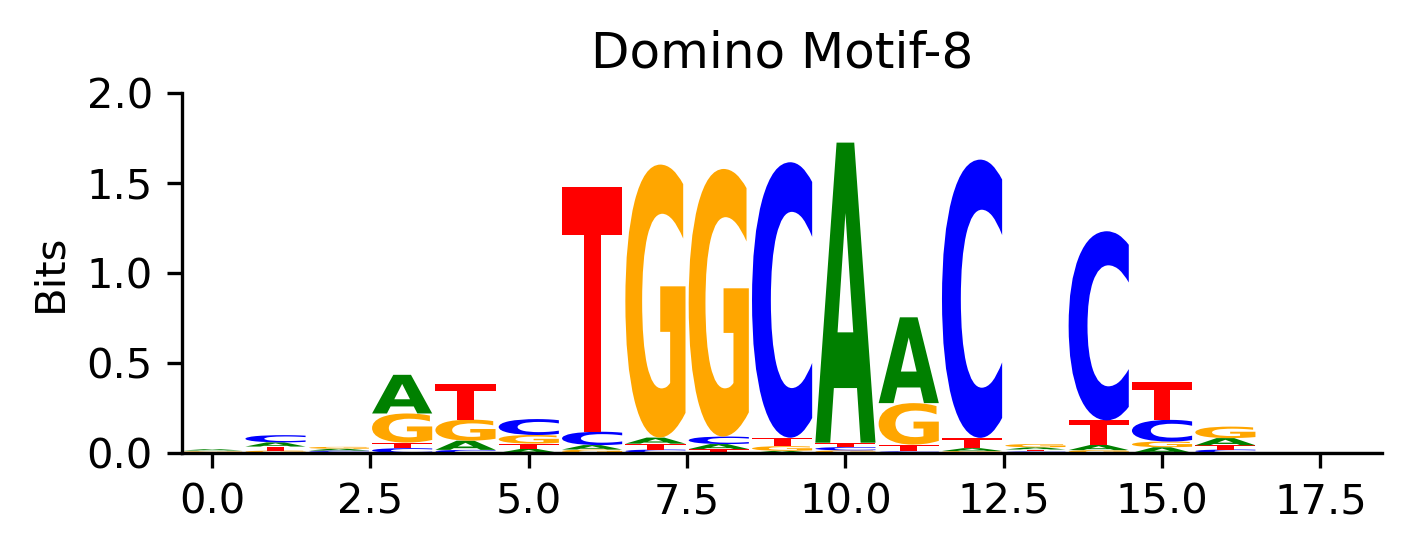

Target shape (4, 12)
Query shape (4, 19)


In [7]:
pattern='neg_patterns.pattern_6'

Motif8_hits = run_tomtom(pattern, motifs)

In [8]:
Motif8_hits

,motif,p_val,q_val
0,CG4854-PA_zf2-5,0.000008,0.005704
1,CG4854-PA_zf1-4,0.000121,0.045323
2,CG30020-PA_zf10-13,0.006412,0.580591
3,CG30020-PA_zf11-14,0.006019,0.580591
4,CG1529-PD_zf3-6,0.008759,0.580591
...,...,...,...
743,CG31441-PA_zf2-5,0.581647,1.000000
744,CG10321-PA_zf2-5,0.410342,1.000000
745,CG10321-PB_zf2-5,0.410342,1.000000
746,crol-PA_zf2-5,0.956365,1.000000


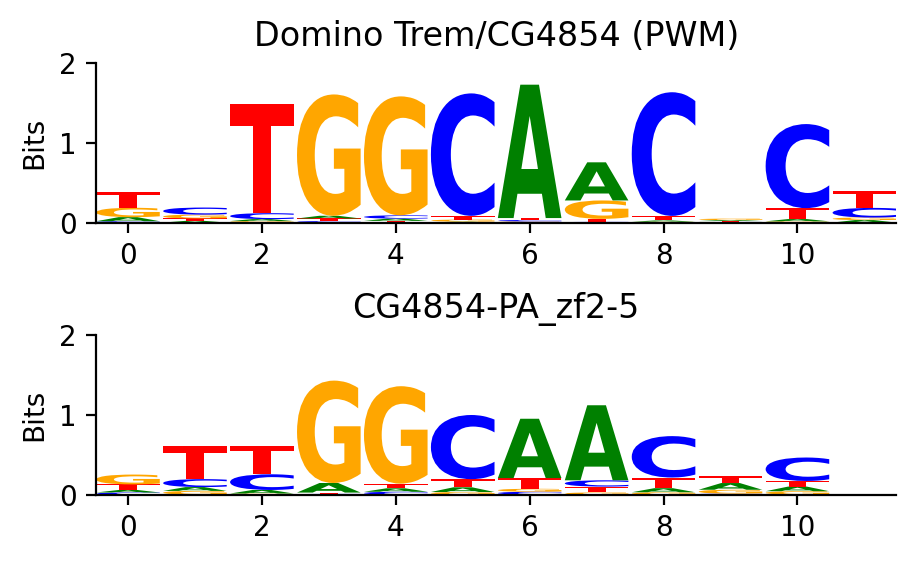

In [9]:
pattern='neg_patterns.pattern_6'

# Get motif
Motif_CWM = nc14_pattern_cwms[pattern]['rev']
Motif_PPM = nc14_pattern_ppms[pattern]['rev']
start, end = trim_cwm_indices(Motif_CWM)
final_Motif_PPM = Motif_PPM[start+1:end]


plot_df = Motif8_hits.iloc[[0]]
fig, axs = init_subplots_exact(len(plot_df) + 1,len(plot_df) + 1,dpi=200, yspace=1.7, y_ratios=[0.2]*(len(plot_df) + 1))
for i, row in plot_df.iterrows():
    pwm = make_logo(final_Motif_PPM)
    plot_weights(pwm, axs[0], f'Domino Trem/CG4854 (PWM)')
    
    tag = row.motif
    pwm = make_logo(reverse_complement_pwm(motifs[tag].T))
    plot_weights(pwm, axs[1], tag)
plt.show()

## AAG3

Running for neg_patterns.pattern_15


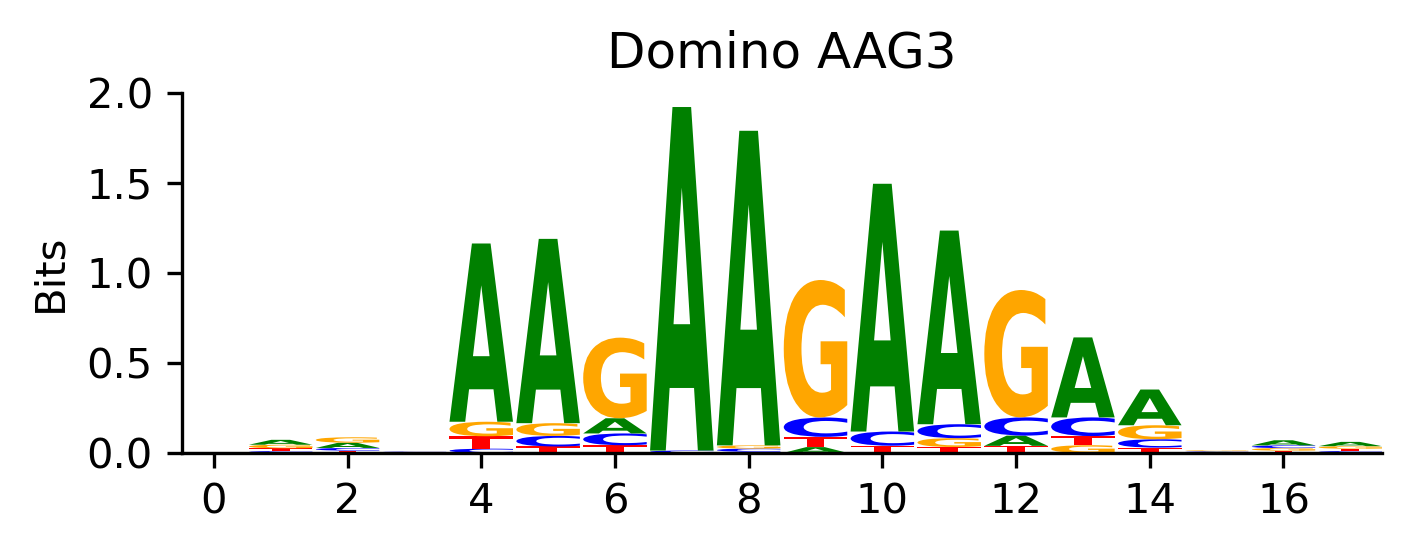

Target shape (4, 12)
Query shape (4, 18)


In [10]:
pattern='neg_patterns.pattern_15'

AAG3_hits = run_tomtom(pattern, motifs)

In [11]:
AAG3_hits

,motif,p_val,q_val
0,CG17385-PA_zf2-5,2.297716e-08,0.000009
1,CG17385-PB_zf2-5,2.297716e-08,0.000009
2,CG17385-PB_zf3-6,6.637188e-07,0.000124
3,CG17385-PA_zf3-6,6.637188e-07,0.000124
4,jim-PF_zf5-8,1.183851e-03,0.038501
...,...,...,...
743,CG31441-PA_zf2-5,9.640529e-01,1.000000
744,crol-PA_zf4-7,1.000000e+00,1.000000
745,crol-PA_zf3-6,1.000000e+00,1.000000
746,crol-PA_zf2-5,1.000000e+00,1.000000


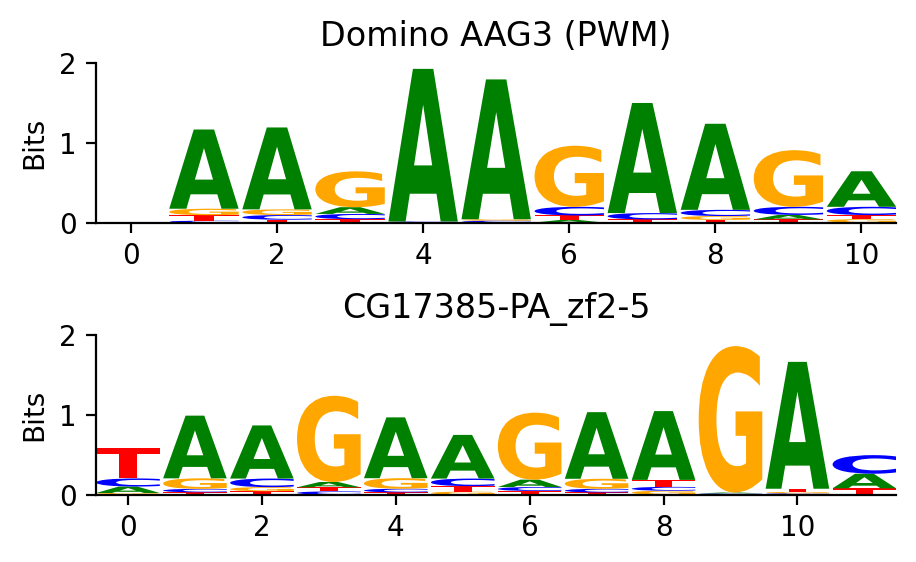

In [12]:
pattern='neg_patterns.pattern_15'

# Get motif
Motif_CWM = nc14_pattern_cwms[pattern]['rev']
Motif_PPM = nc14_pattern_ppms[pattern]['rev']
start, end = trim_cwm_indices(Motif_CWM)
final_Motif_PPM = Motif_PPM[start:end-1]


plot_df = AAG3_hits.iloc[[0]]
fig, axs = init_subplots_exact(len(plot_df) + 1,len(plot_df) + 1,dpi=200, yspace=1.7, y_ratios=[0.2]*(len(plot_df) + 1))
for i, row in plot_df.iterrows():
    pwm = make_logo(final_Motif_PPM)
    plot_weights(pwm, axs[0], f'Domino {npatterns2targets[pattern][0]} (PWM)')
    
    tag = row.motif
    pwm = make_logo(motifs[tag].T)
    plot_weights(pwm, axs[1], tag)
plt.show()